# Лабораторная работа № 2
## Базовая модель MNIST и проверка устойчивости входов
Цель: обучить воспроизводимый классификатор, проверить качество, валидацию входов и чувствительность к небольшим изменениям.

In [3]:
from pathlib import Path
import json
import os
import sys
from IPython.display import display, Image

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
if not (ROOT / 'src' / 'lab2.py').exists():
    raise RuntimeError('Откройте Notebook из каталога проекта')
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

def show_json(path):
    data = json.loads(Path(path).read_text(encoding='utf-8'))
    print(json.dumps(data, ensure_ascii=False, indent=2))
    return data

## 1. Проверка данных и обучение
Используется официальный тест MNIST. Точные пересечения с тестом, повторные обучающие изображения и противоречивые обучающие группы исключаются до стратифицированного разделения. Seed — 42.

Если модель уже обучена из терминала, Notebook использует сохранённый результат и не перезаписывает baseline.

In [4]:
from src.lab2 import train_run
from src.model import load_model

if not Path('metrics/baseline.json').exists():
    train_run()
else:
    model = load_model()
    print('Загружена ранее обученная модель; SHA256 проверен.')

data_check = show_json('reports/lab2/data_check.json')

Загружена ранее обученная модель; SHA256 проверен.
{
  "dataset_sha256": "731c5ac602752760c8e48fbffcf8c3b850d9dc2a2aedcf2cc48468fc17b673d1",
  "seed": 42,
  "original_train_size": 60000,
  "original_test_size": 10000,
  "pixel_dtype": "uint8",
  "label_dtype": "uint8",
  "pixel_min": 0,
  "pixel_max": 255,
  "missing_values": 0,
  "train_duplicate_extra_copies": 0,
  "test_duplicate_extra_copies": 0,
  "train_test_shared_unique_images": 0,
  "conflicting_train_image_groups": 0,
  "removed_from_original_train": 0,
  "train_size": 48000,
  "validation_size": 12000,
  "test_size": 10000,
  "train_class_counts": [
    4738,
    5394,
    4766,
    4905,
    4674,
    4337,
    4734,
    5012,
    4681,
    4759
  ],
  "validation_class_counts": [
    1185,
    1348,
    1192,
    1226,
    1168,
    1084,
    1184,
    1253,
    1170,
    1190
  ],
  "test_class_counts": [
    980,
    1135,
    1032,
    1010,
    982,
    892,
    958,
    1028,
    974,
    1009
  ],
  "split_policy": "

### Ограничения данных
MNIST достаточно разнообразен для учебного сравнения простого классификатора с константным ориентиром: представлены все десять классов и множество вариантов написания. Однако набор не представляет произвольные фотографии, цветные изображения и сложные фоны. В архиве отсутствуют идентификаторы авторов, а проверка точных дубликатов не выявляет все похожие изображения.

In [5]:
training = show_json('metrics/training.json')

{
  "seed": 42,
  "model_parameters": {
    "alpha": 0.0001,
    "average": true,
    "class_weight": null,
    "early_stopping": false,
    "epsilon": 0.1,
    "eta0": 0.01,
    "fit_intercept": true,
    "l1_ratio": 0.15,
    "learning_rate": "optimal",
    "loss": "log_loss",
    "max_iter": 50,
    "n_iter_no_change": 5,
    "n_jobs": 1,
    "penalty": "l2",
    "power_t": 0.5,
    "random_state": 42,
    "shuffle": true,
    "tol": 0.001,
    "validation_fraction": 0.1,
    "verbose": 0,
    "warm_start": false
  },
  "training_seconds": 19.679672116000802,
  "iterations": 28,
  "train_size": 48000,
  "validation_size": 12000,
  "test_size": 10000,
  "preprocessing": "reshape to 784, float32, divide by 255",
  "python_version": "3.14.4",
  "numpy_version": "2.5.4",
  "sklearn_version": "1.9.1",
  "selection_policy": "Parameters fixed before test evaluation; no hyperparameter search on test data."
}


## 2. Качество модели
Основная метрика — macro-F1: каждый класс имеет одинаковый вес. Дополнительно рассчитываются Accuracy, macro-Precision, macro-Recall и метрики отдельных классов.

In [6]:
baseline = show_json('metrics/baseline.json')

{
  "model_version": "lab2-v1",
  "model_type": "SGDClassifier linear logistic classifier",
  "primary_metric": "f1_macro",
  "primary_value": 0.9137887783942518,
  "test_size": 10000,
  "dataset_version": "mnist-npz-sha256:731c5ac602752760c8e48fbffcf8c3b850d9dc2a2aedcf2cc48468fc17b673d1",
  "model_sha256": "a1411713f8b02c211befe9c8fc565bd575f240ede992dfd1c41dafb82801927c",
  "test_metrics": {
    "accuracy": 0.9152,
    "precision_macro": 0.913859302210288,
    "recall_macro": 0.9140544445776853,
    "f1_macro": 0.9137887783942518
  },
  "validation_metrics": {
    "accuracy": 0.9109166666666667,
    "precision_macro": 0.909764016806955,
    "recall_macro": 0.9098661082064424,
    "f1_macro": 0.909720546720264
  },
  "dummy_test_metrics": {
    "accuracy": 0.1135,
    "precision_macro": 0.01135,
    "recall_macro": 0.1,
    "f1_macro": 0.0203861697350696
  },
  "per_class": {
    "0": {
      "precision": 0.9419291338582677,
      "recall": 0.976530612244898,
      "f1-score": 0.95891

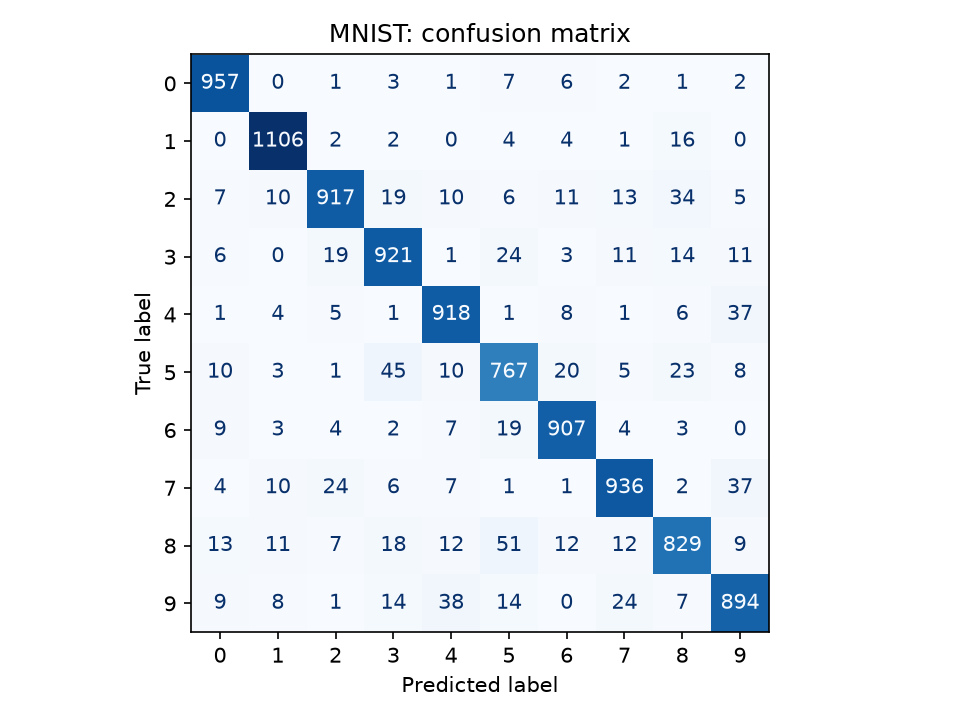

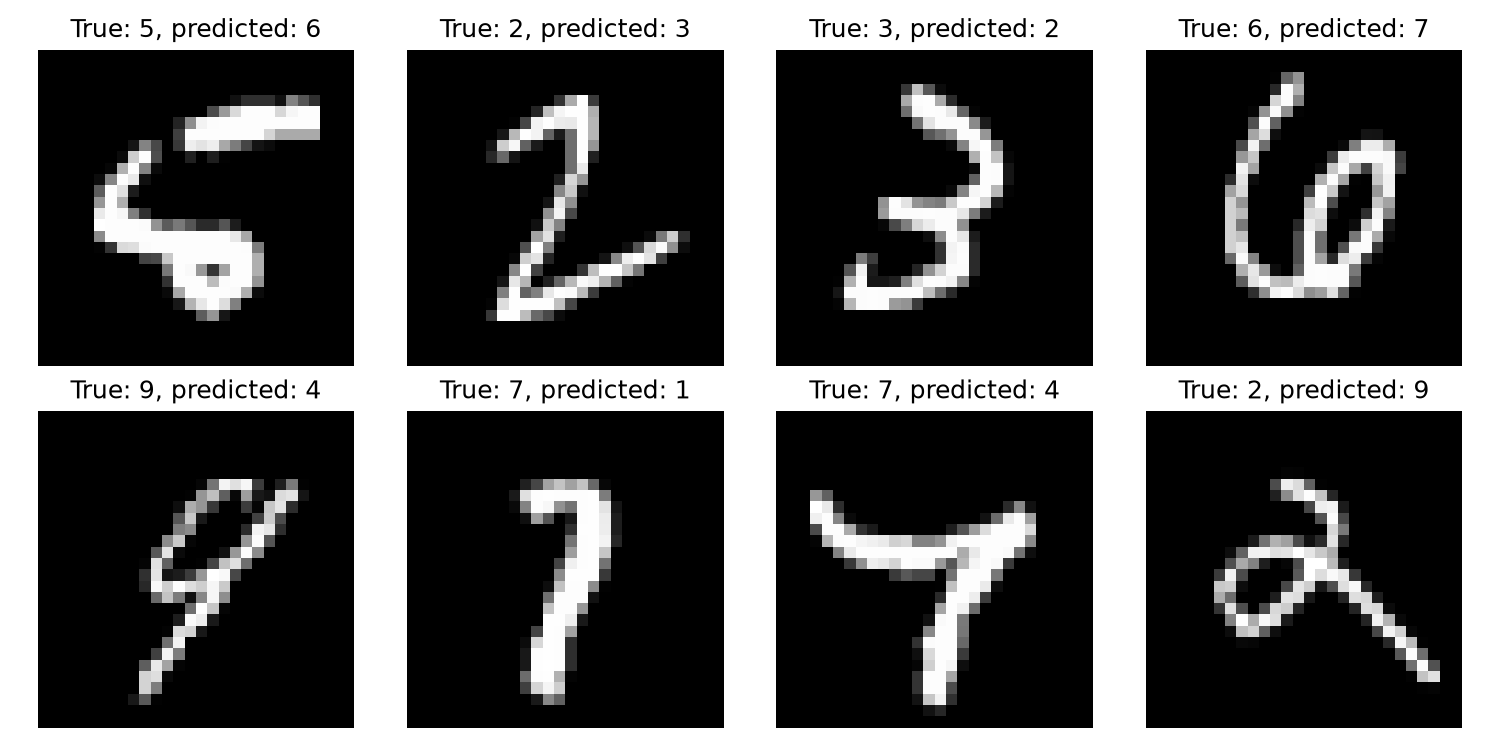

[
  {
    "test_index": 8,
    "true": 5,
    "predicted": 6
  },
  {
    "test_index": 38,
    "true": 2,
    "predicted": 3
  },
  {
    "test_index": 63,
    "true": 3,
    "predicted": 2
  },
  {
    "test_index": 66,
    "true": 6,
    "predicted": 7
  },
  {
    "test_index": 92,
    "true": 9,
    "predicted": 4
  },
  {
    "test_index": 111,
    "true": 7,
    "predicted": 1
  },
  {
    "test_index": 124,
    "true": 7,
    "predicted": 4
  },
  {
    "test_index": 149,
    "true": 2,
    "predicted": 9
  }
]


In [7]:
display(Image(filename='reports/lab2/confusion_matrix.png'))
display(Image(filename='reports/lab2/errors.png'))
errors = show_json('reports/lab2/error_examples.json')

### Разбор ошибочных предсказаний
После просмотра рисунка опишите 2–3 конкретных примера: истинный класс, ответ модели и видимое сходство начертания. Линейный классификатор использует пиксели и ограниченно учитывает смещения и изменения формы штрихов.

## 3. Валидация и автоматические тесты
Допускаются массивы 28 × 28 и пакеты до 64 изображений. PNG ограничен 64 КиБ и 784 пикселями; поддерживается режим L. Некорректные значения отклоняются до вызова модели.

In [8]:
print(Path('reports/lab2/pytest.txt').read_text(encoding='utf-8'))

============================= test session starts ==============================
platform linux -- Python 3.14.4, pytest-9.2.0, pluggy-1.7.0 -- /home/mluser/ml-project/.venv/bin/python
cachedir: .pytest_cache
rootdir: /home/mluser/ml-project
plugins: platformdirs-4.14.5, anyio-4.16.0
collecting ... collected 17 items

tests/test_validation.py::test_invalid_array_does_not_call_model[wrong_type] PASSED [  5%]
tests/test_validation.py::test_invalid_array_does_not_call_model[wrong_shape] PASSED [ 11%]
tests/test_validation.py::test_invalid_array_does_not_call_model[empty_batch] PASSED [ 17%]
tests/test_validation.py::test_invalid_array_does_not_call_model[nan] PASSED [ 23%]
tests/test_validation.py::test_invalid_array_does_not_call_model[inf] PASSED [ 29%]
tests/test_validation.py::test_invalid_array_does_not_call_model[negative_pixel] PASSED [ 35%]
tests/test_validation.py::test_invalid_array_does_not_call_model[pixel_above_255] PASSED [ 41%]
tests/test_validation.py::test_invalid_array_d

## 4. Эксперимент с устойчивостью
Для 20 фиксированных тестовых изображений добавлен гауссовский шум с sigma=8. Предполагается, что небольшое изменение сохраняет истинную цифру; это проверяется также визуально.

{
  "seed": 42,
  "sample_size": 20,
  "change": "Gaussian pixel noise, sigma=8 on the 0-255 scale",
  "changed_answer_fraction": 0.0,
  "accuracy_before": 0.95,
  "accuracy_after": 0.95,
  "assumption": "Small noise is assumed to preserve digit identity.",
  "unusual_input": "Uniform random pixel noise, not a handwritten digit.",
  "unusual_prediction": 3,
  "unusual_input_rejected": false,
  "conclusion": "Schema validation does not detect semantic anomalies. The classifier always selects one of ten classes.",
  "next_measure": "Evaluate noise augmentation and a rejection policy on a separate validation set of non-digit images.",
  "objects": [
    {
      "test_index": 3,
      "true": 0,
      "original_prediction": 0,
      "changed_prediction": 0,
      "prediction_changed": false
    },
    {
      "test_index": 10,
      "true": 0,
      "original_prediction": 0,
      "changed_prediction": 0,
      "prediction_changed": false
    },
    {
      "test_index": 2,
      "true": 1

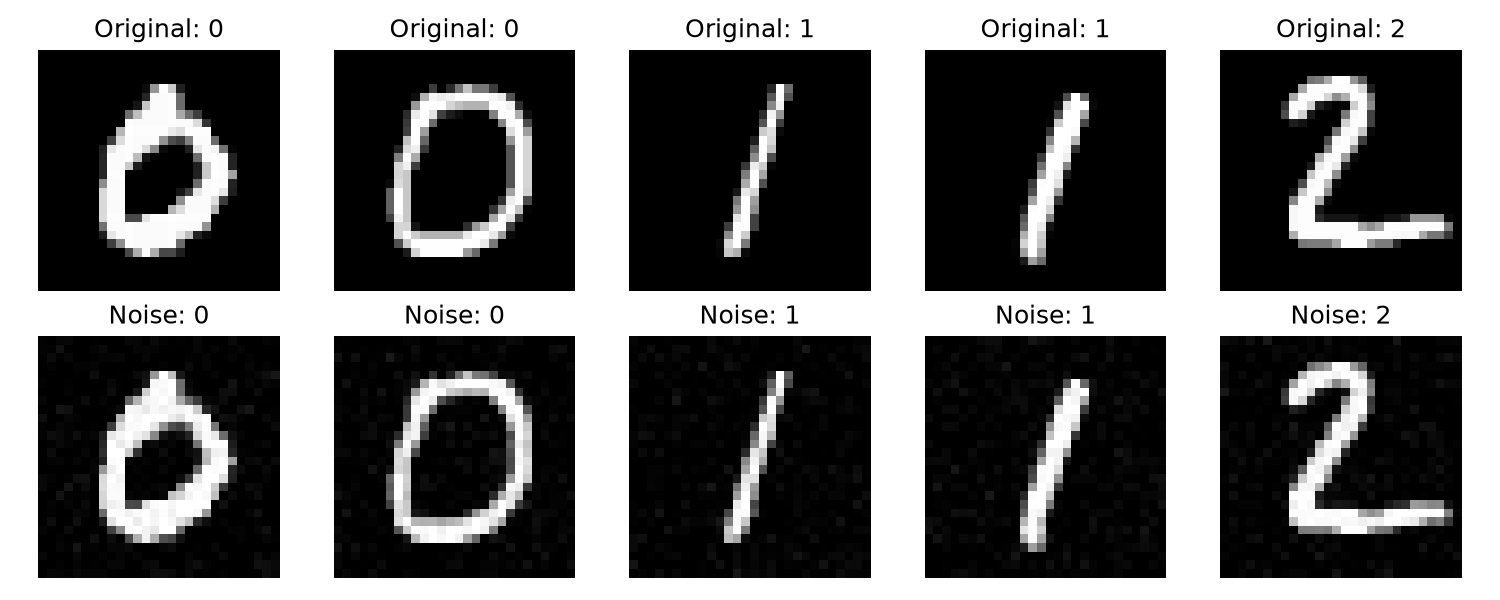

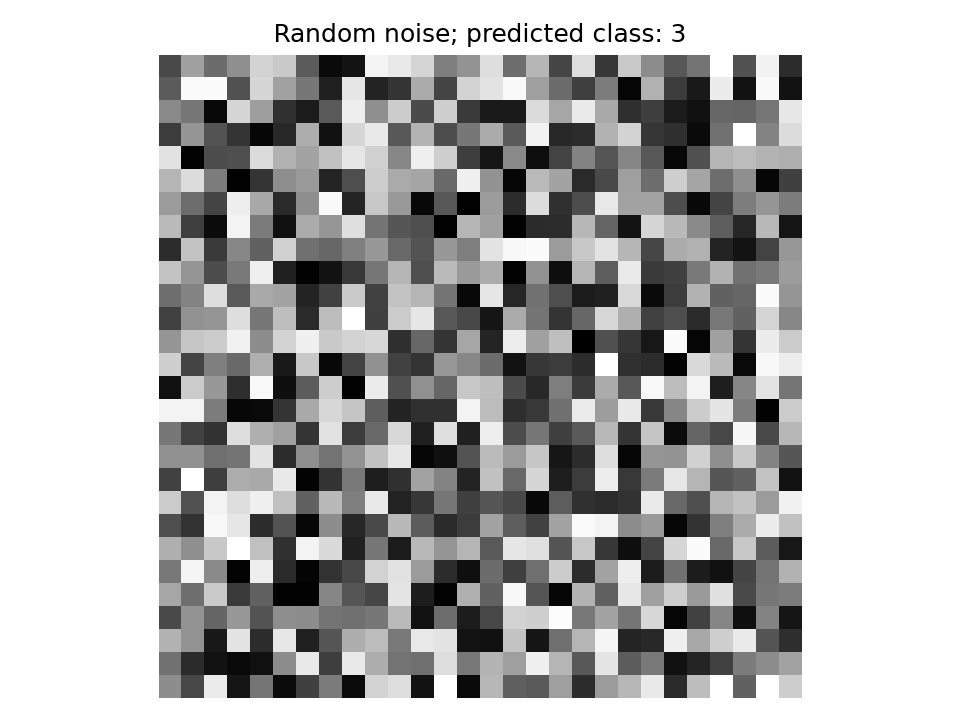

Доля изменившихся ответов: 0.0
Accuracy до: 0.95
Accuracy после: 0.95


In [9]:
robustness = show_json('reports/lab2/robustness.json')
display(Image(filename='reports/lab2/robustness.png'))
display(Image(filename='reports/lab2/unusual_input.png'))
print('Доля изменившихся ответов:', robustness['changed_answer_fraction'])
print('Accuracy до:', robustness['accuracy_before'])
print('Accuracy после:', robustness['accuracy_after'])

## 5. Вывод
Построена линейная базовая модель, сохранены параметры и метрики. Валидация ограничивает структуру и размер входов. Случайный шум показывает, что формально допустимый вход не обязательно содержит цифру. Дальнейшая проверка — обучение с шумовыми искажениями и оценка механизма отказа на отдельной выборке нецифровых изображений. Эксперимент на 20 объектах не доказывает общую устойчивость модели.